# Air Passenger Traffic Forecasting
**Business Statistics using Python · MCA Semester I · Course 26MCAC103**

Dataset: *Air Traffic Passenger Statistics*, San Francisco International Airport (SFO), published on data.sf.gov.
This notebook covers every step of the project: preprocessing, EDA, descriptive statistics, visualisation, hypothesis testing, regression, forecasting and recommendations.

## 1. Setup

In [1]:
import warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy import stats
import statsmodels.api as sm
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.holtwinters import ExponentialSmoothing, SimpleExpSmoothing, Holt
from statsmodels.stats.stattools import durbin_watson

warnings.filterwarnings("ignore")
np.random.seed(42)

# Colour palette used across all charts
INK, GREY, RUST, BLUE, GREEN, SAND = "#3A3631", "#6B655B", "#B5472E", "#3F6590", "#4F8A6B", "#F2E6D0"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": GREY, "ytick.color": GREY, "axes.grid": True,
    "grid.color": "#E4DDD0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
})
FIG = "figs/"          # folder where charts are saved for the report
import os; os.makedirs(FIG, exist_ok=True)
results = {}            # key numbers are collected here and reused in the report

## 2. Dataset description

In [2]:
CSV = "Air_Traffic_Passenger_Statistics.csv"
raw = pd.read_csv(CSV)
print("Rows, columns:", raw.shape)
raw.head()

Rows, columns: (38196, 15)


,Activity Period,Activity Period Start Date,Operating Airline,Operating Airline IATA Code,Published Airline,Published Airline IATA Code,GEO Summary,GEO Region,Activity Type Code,Price Category Code,Terminal,Boarding Area,Passenger Count,data_as_of,data_loaded_at
0,199907,1999/07/01,ATA Airlines,TZ,ATA Airlines,TZ,Domestic,US,Deplaned,Low Fare,Terminal 1,B,31432,2025/06/20 01:00:30 PM,2025/07/20 03:02:25 PM
1,199907,1999/07/01,ATA Airlines,TZ,ATA Airlines,TZ,Domestic,US,Enplaned,Low Fare,Terminal 1,B,31353,2025/06/20 01:00:30 PM,2025/07/20 03:02:25 PM
2,199907,1999/07/01,ATA Airlines,TZ,ATA Airlines,TZ,Domestic,US,Thru / Transit,Low Fare,Terminal 1,B,2518,2025/06/20 01:00:30 PM,2025/07/20 03:02:25 PM
3,199907,1999/07/01,Aeroflot Russian International Airlines,NaN,Aeroflot Russian International Airlines,NaN,International,Europe,Deplaned,Other,Terminal 2,D,1324,2025/06/20 01:00:30 PM,2025/07/20 03:02:25 PM
4,199907,1999/07/01,Aeroflot Russian International Airlines,NaN,Aeroflot Russian International Airlines,NaN,International,Europe,Enplaned,Other,Terminal 2,D,1198,2025/06/20 01:00:30 PM,2025/07/20 03:02:25 PM


In [3]:
# Data dictionary: type, missing values and number of distinct values for every column
info = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "unique": raw.nunique(),
    "example": raw.iloc[0],
})
info

,dtype,missing,unique,example
Activity Period,int64,0,311,199907
Activity Period Start Date,str,0,311,1999/07/01
Operating Airline,str,0,138,ATA Airlines
Operating Airline IATA Code,str,316,114,TZ
Published Airline,str,0,124,ATA Airlines
Published Airline IATA Code,str,316,103,TZ
GEO Summary,str,0,2,Domestic
GEO Region,str,0,9,US
Activity Type Code,str,0,3,Deplaned
Price Category Code,str,0,2,Low Fare


## 3. Data preprocessing

In [4]:
df = raw.copy()

# 1. Convert YYYYMM integer into a proper month-start date
df["date"] = pd.to_datetime(df["Activity Period"].astype(str), format="%Y%m")

# 2. Standardise airline names: the source uses a separate label for United before July 2013
df["airline"] = df["Published Airline"].replace({"United Airlines - Pre 07/01/2013": "United Airlines"})

# 3. Quality checks
n_dup = int(df.duplicated().sum())
print("Duplicate rows          :", n_dup)
print("Missing airline codes   :", int(df["Operating Airline IATA Code"].isna().sum()))
print("Negative passenger rows :", int((df["Passenger Count"] < 0).sum()))
print("Date range              :", df["date"].min().date(), "to", df["date"].max().date())

# 4. Aggregate all airlines/terminals into one monthly total (in millions)
monthly = df.groupby("date")["Passenger Count"].sum().asfreq("MS") / 1e6
monthly.name = "passengers_m"

# 5. Confirm there are no gaps in the monthly series
print("Months in series        :", len(monthly), "| missing months:", int(monthly.isna().sum()))

results.update(rows=len(df), cols=df.shape[1], duplicates=n_dup,
               missing_codes=int(df["Operating Airline IATA Code"].isna().sum()),
               months=len(monthly), start=str(monthly.index[0].date()), end=str(monthly.index[-1].date()))
monthly.head()

Duplicate rows          : 0
Missing airline codes   : 316
Negative passenger rows : 0
Date range              : 1999-07-01 to 2025-05-01
Months in series        : 311 | missing months: 0


date
1999-07-01    3.976746
1999-08-01    3.972694
1999-09-01    3.341964
1999-10-01    3.468846
1999-11-01    3.145240
Freq: MS, Name: passengers_m, dtype: float64

## 4. Exploratory data analysis (EDA)

GEO Summary
Domestic         76.3
International    23.7 

Activity Type Code
Deplaned          49.9
Enplaned          49.8
Thru / Transit     0.4 

Terminal
Terminal 3       41.4
International    25.3
Terminal 1       23.5
Terminal 2        9.8
Other             0.0 



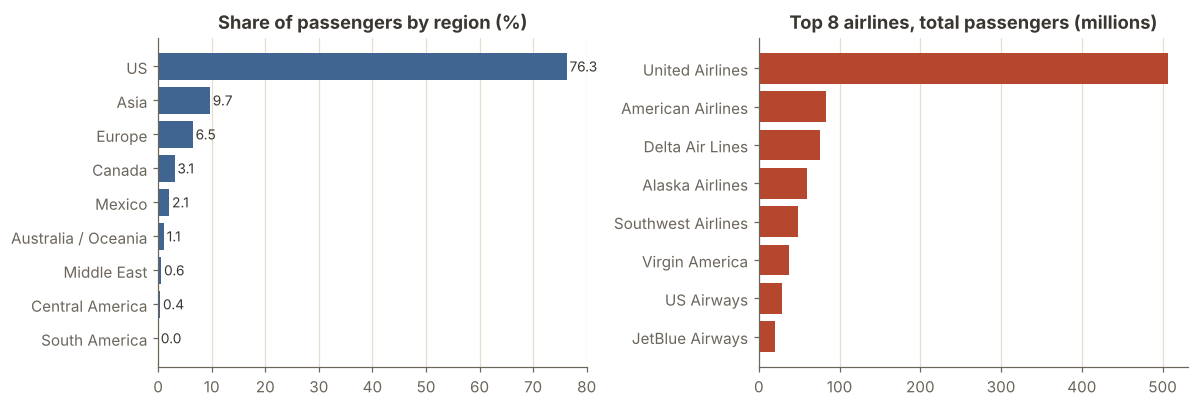

In [5]:
# Who travels through SFO? Share of all passengers by key categories
def share(col):
    s = df.groupby(col)["Passenger Count"].sum().sort_values(ascending=False)
    return (s / s.sum() * 100).round(1)

for col in ["GEO Summary", "Activity Type Code", "Terminal"]:
    print(share(col).to_string(), "\n")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
reg = share("GEO Region")[::-1]
axes[0].barh(reg.index, reg.values, color=BLUE); axes[0].set_title("Share of passengers by region (%)")
axes[0].grid(axis="y", visible=False)
for i, v in enumerate(reg.values): axes[0].text(v + 0.5, i, f"{v:.1f}", va="center", fontsize=9)
top = (df.groupby("airline")["Passenger Count"].sum().sort_values(ascending=False).head(8)[::-1] / 1e6)
axes[1].barh(top.index, top.values, color=RUST); axes[1].set_title("Top 8 airlines, total passengers (millions)")
axes[1].grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig(FIG + "eda_region_airlines.png"); plt.show()
results["geo_share"] = share("GEO Summary").to_dict()
results["region_share"] = share("GEO Region").to_dict()

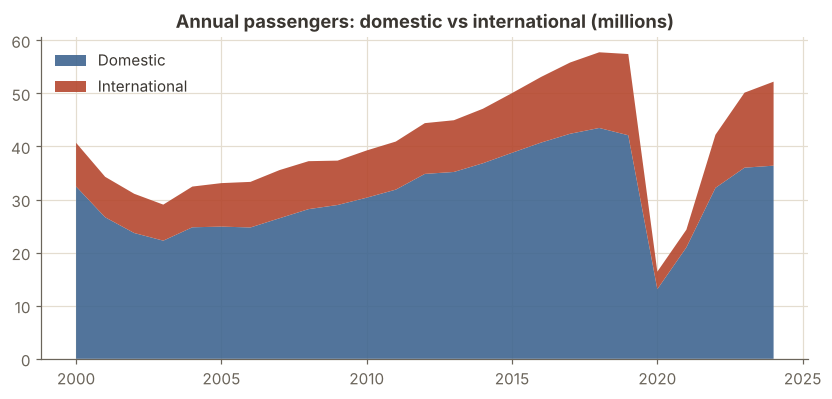

26.65087955684863 30.307422741429725


In [6]:
# Domestic vs International over time: has the mix changed?
mix = df.groupby([df["date"].dt.year, "GEO Summary"])["Passenger Count"].sum().unstack() / 1e6
mix = mix.loc[2000:2024]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.stackplot(mix.index, mix["Domestic"], mix["International"], labels=["Domestic", "International"], colors=[BLUE, RUST], alpha=0.9)
ax.set_title("Annual passengers: domestic vs international (millions)"); ax.legend(loc="upper left", frameon=False)
plt.savefig(FIG + "eda_mix.png"); plt.show()
results["intl_share_2019"] = float(mix.loc[2019, "International"] / mix.loc[2019].sum() * 100)
results["intl_share_2024"] = float(mix.loc[2024, "International"] / mix.loc[2024].sum() * 100)
print(results["intl_share_2019"], results["intl_share_2024"])

## 5. Descriptive statistics

In [7]:
s = monthly
desc = pd.Series({
    "count": s.count(), "mean": s.mean(), "median": s.median(), "std": s.std(),
    "min": s.min(), "max": s.max(), "Q1": s.quantile(.25), "Q3": s.quantile(.75),
    "skewness": s.skew(), "kurtosis": s.kurt(), "CV (%)": s.std() / s.mean() * 100,
})
print(desc.round(3).to_string())
print("Lowest month :", s.idxmin().date(), round(s.min(), 3))
print("Highest month:", s.idxmax().date(), round(s.max(), 3))
results["desc"] = desc.round(4).to_dict()
results["min_month"] = str(s.idxmin().date()); results["max_month"] = str(s.idxmax().date())

# Summer (Jun-Aug) vs other months, using the pre-COVID period (to Dec 2019)
pre = s[:"2019-12-01"]
summer = pre[pre.index.month.isin([6, 7, 8])].mean(); other = pre[~pre.index.month.isin([6, 7, 8])].mean()
print(f"Pre-COVID: summer {summer:.2f}M vs other months {other:.2f}M ({(summer/other-1)*100:.1f}% higher)")
results.update(summer=summer, other=other, summer_uplift=(summer/other-1)*100)

count       311.000
mean          3.416
median        3.411
std           0.995
min           0.139
max           5.742
Q1            2.772
Q3            4.135
skewness     -0.359
kurtosis      0.557
CV (%)       29.114
Lowest month : 2020-04-01 0.139
Highest month: 2019-08-01 5.742
Pre-COVID: summer 4.01M vs other months 3.30M (21.5% higher)


## 6. Data visualisation

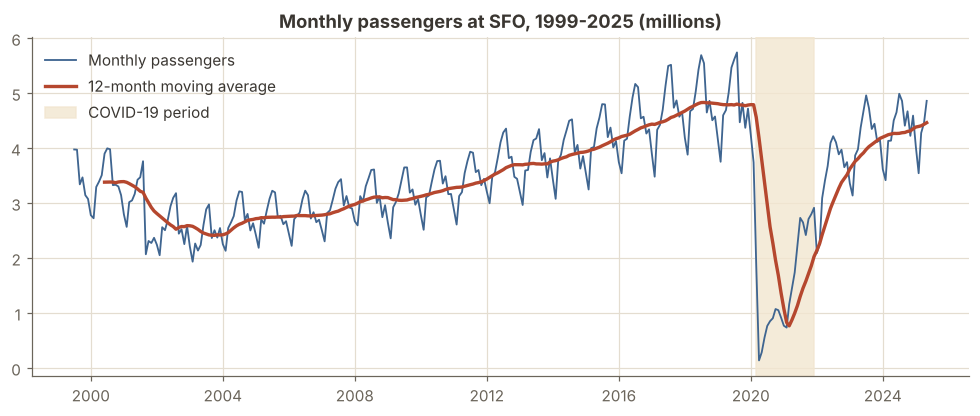

In [8]:
# 6.1 Monthly series with 12-month moving average
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(monthly.index, monthly, color=BLUE, lw=1.2, label="Monthly passengers")
ax.plot(monthly.index, monthly.rolling(12).mean(), color=RUST, lw=2.2, label="12-month moving average")
ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2021-12-01"), color=SAND, alpha=.8, label="COVID-19 period")
ax.set_title("Monthly passengers at SFO, 1999-2025 (millions)"); ax.legend(frameon=False, loc="upper left")
plt.savefig(FIG + "viz_monthly.png"); plt.show()

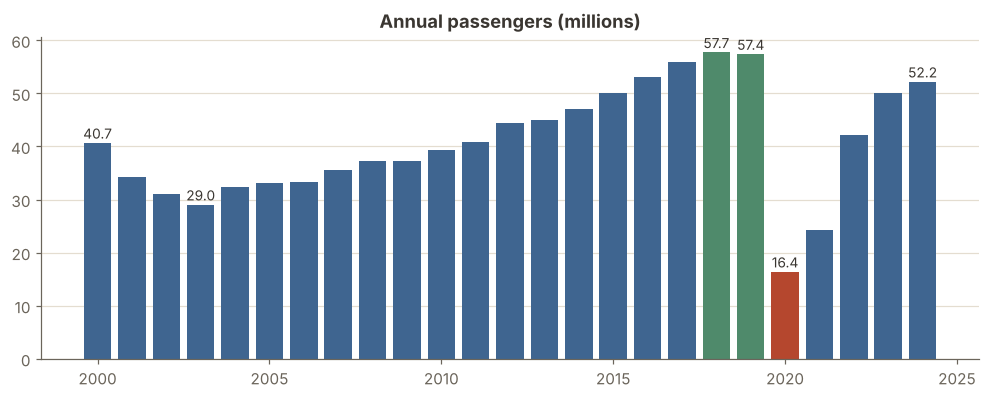

date
1999    20.98
2000    40.69
2001    34.29
2002    31.09
2003    29.05
2004    32.45
2005    33.10
2006    33.33
2007    35.55
2008    37.23
2009    37.34
2010    39.25
2011    40.93
2012    44.40
2013    44.95
2014    47.11
2015    50.06
2016    53.10
2017    55.82
2018    57.75
2019    57.42
2020    16.42
2021    24.33
2022    42.21
2023    50.14
2024    52.21
2025    21.17


In [9]:
# 6.2 Annual totals (2000-2024 are complete years)
annual = monthly.groupby(monthly.index.year).sum()
full = annual.loc[2000:2024]
fig, ax = plt.subplots(figsize=(11, 3.8))
cols = [RUST if y == 2020 else (GREEN if y in (2018, 2019) else BLUE) for y in full.index]
ax.bar(full.index, full.values, color=cols)
ax.set_title("Annual passengers (millions)"); ax.grid(axis="x", visible=False)
for y in (2000, 2003, 2018, 2019, 2020, 2024): ax.text(y, full[y] + 0.8, f"{full[y]:.1f}", ha="center", fontsize=9)
plt.savefig(FIG + "viz_annual.png"); plt.show()
print(annual.round(2).to_string())
results["annual"] = {int(k): round(float(v), 3) for k, v in annual.items()}

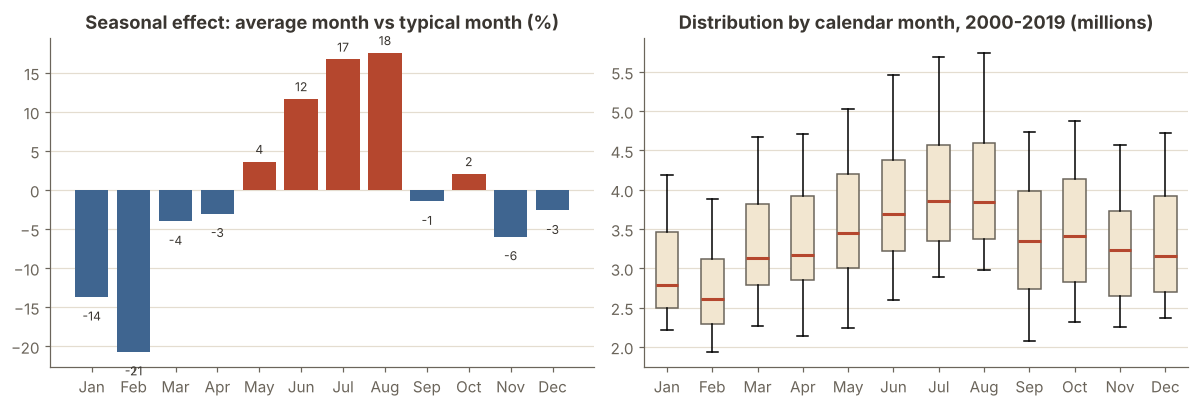

In [10]:
# 6.3 Seasonality: average month relative to the overall average (2000-2019, complete pre-COVID years)
base = monthly["2000-01-01":"2019-12-01"]
idx = (base.groupby(base.index.month).mean() / base.mean() - 1) * 100
names = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar(names, idx.values, color=[RUST if v > 0 else BLUE for v in idx.values])
axes[0].set_title("Seasonal effect: average month vs typical month (%)"); axes[0].grid(axis="x", visible=False)
for i, v in enumerate(idx.values): axes[0].text(i, v + (1 if v > 0 else -3), f"{v:.0f}", ha="center", fontsize=8)
# distribution of each calendar month across years (box plot)
axes[1].boxplot([base[base.index.month == m] for m in range(1, 13)], tick_labels=names, patch_artist=True,
                boxprops=dict(facecolor=SAND, color=GREY), medianprops=dict(color=RUST, lw=2))
axes[1].set_title("Distribution by calendar month, 2000-2019 (millions)"); axes[1].grid(axis="x", visible=False)
plt.tight_layout(); plt.savefig(FIG + "viz_seasonal.png"); plt.show()
results["season_idx"] = {names[i]: round(float(v), 2) for i, v in enumerate(idx.values)}

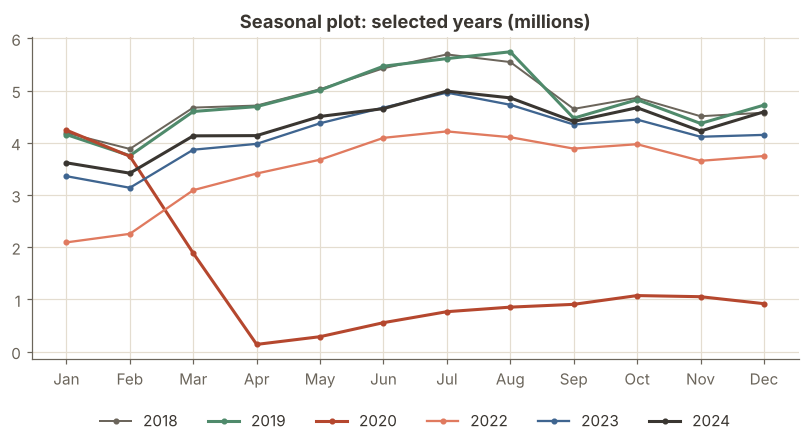

In [11]:
# 6.4 Seasonal plot: one line per recent year
fig, ax = plt.subplots(figsize=(9, 3.8))
for y, c, lw in [(2018, GREY, 1.3), (2019, GREEN, 2), (2020, RUST, 2), (2022, "#E07A5F", 1.5), (2023, BLUE, 1.5), (2024, INK, 2)]:
    d = monthly[str(y)]; ax.plot(d.index.month, d.values, color=c, lw=lw, marker="o", ms=3, label=str(y))
ax.set_xticks(range(1, 13)); ax.set_xticklabels(names); ax.legend(ncol=6, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.set_title("Seasonal plot: selected years (millions)")
plt.savefig(FIG + "viz_seasonal_lines.png"); plt.show()

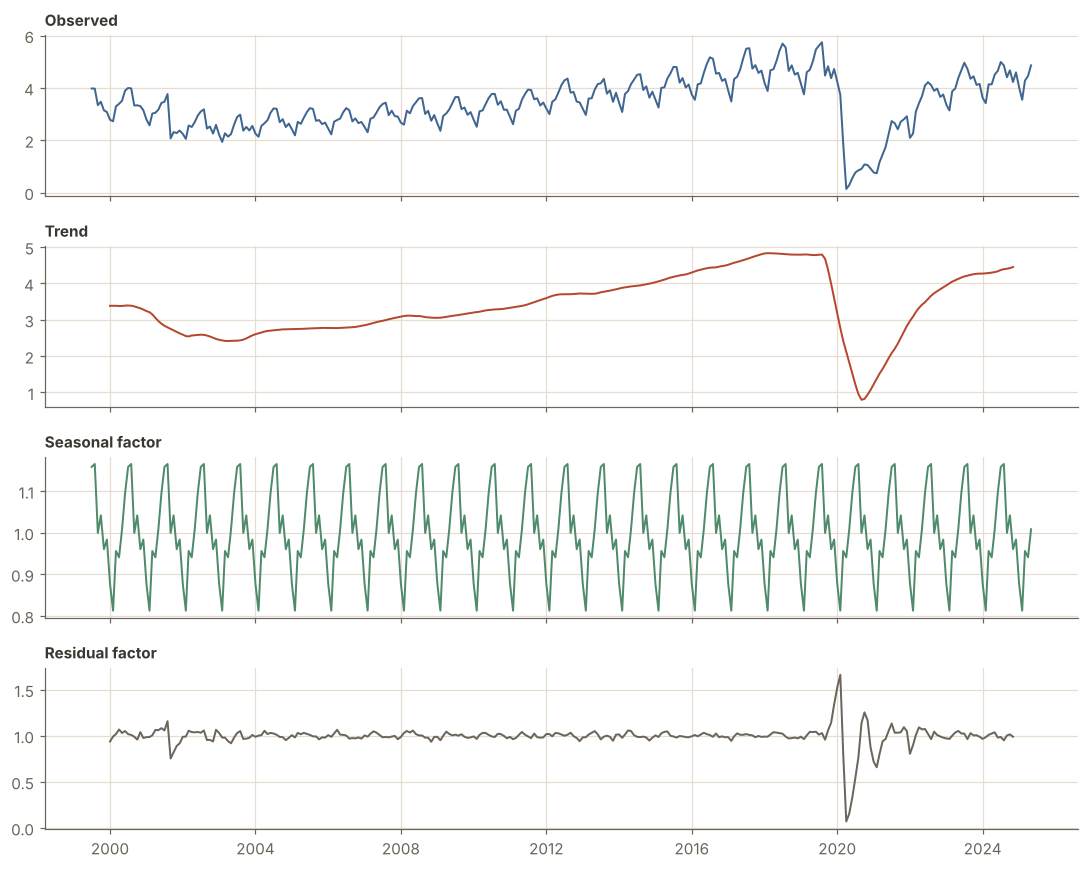

In [12]:
# 6.5 Classical decomposition (multiplicative) on the full series
dec = seasonal_decompose(monthly, model="multiplicative", period=12)
fig, axes = plt.subplots(4, 1, figsize=(10, 8), sharex=True)
for ax, (t, d, c) in zip(axes, [("Observed", dec.observed, BLUE), ("Trend", dec.trend, RUST), ("Seasonal factor", dec.seasonal, GREEN), ("Residual factor", dec.resid, GREY)]):
    ax.plot(d, color=c, lw=1.3); ax.set_title(t, loc="left", fontsize=10)
plt.tight_layout(); plt.savefig(FIG + "viz_decomposition.png"); plt.show()

## 7. Trend analysis

In [13]:
a = results["annual"]
cagr = ((a[2019] / a[2000]) ** (1 / 19) - 1) * 100
drop20 = (a[2020] / a[2019] - 1) * 100
rec24 = a[2024] / a[2019] * 100
print(f"Growth 2000-2019 : {cagr:.2f}% per year")
print(f"2020 vs 2019     : {drop20:.1f}%")
print(f"2024 vs 2019     : {rec24:.1f}% of the 2019 level")
results.update(cagr=cagr, drop20=drop20, rec24=rec24)

Growth 2000-2019 : 1.83% per year
2020 vs 2019     : -71.4%
2024 vs 2019     : 90.9% of the 2019 level


## 8. Inferential statistics: was 2024 still below 2019?
Hypotheses (paired by calendar month so that seasonality cancels out):
- H0: mean monthly passengers in 2019 = mean in 2024
- H1: the means differ  (α = 0.05)

Mean difference (2024-2019): -0.434M per month
95% CI: [-0.607, -0.261]
Paired t = -5.521, df = 11, p = 0.00018
Cohen's dz = -1.59
Normality of differences (Shapiro-Wilk) p = 0.420
Wilcoxon signed-rank (robustness) p = 0.00049


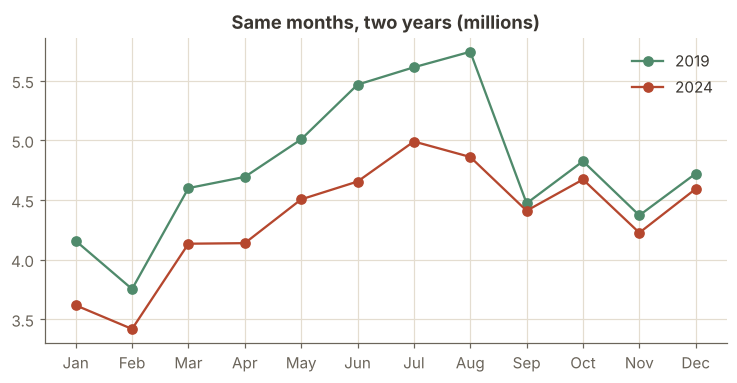

In [14]:
y19 = monthly["2019"].values; y24 = monthly["2024"].values
diff = y24 - y19
t, p = stats.ttest_rel(y24, y19)
ci = stats.t.interval(0.95, len(diff) - 1, loc=diff.mean(), scale=stats.sem(diff))
dz = diff.mean() / diff.std(ddof=1)
sh_w, sh_p = stats.shapiro(diff)
w_stat, w_p = stats.wilcoxon(y24, y19)
print(f"Mean difference (2024-2019): {diff.mean():.3f}M per month")
print(f"95% CI: [{ci[0]:.3f}, {ci[1]:.3f}]")
print(f"Paired t = {t:.3f}, df = {len(diff)-1}, p = {p:.5f}")
print(f"Cohen's dz = {dz:.2f}")
print(f"Normality of differences (Shapiro-Wilk) p = {sh_p:.3f}")
print(f"Wilcoxon signed-rank (robustness) p = {w_p:.5f}")
results.update(mean_diff=diff.mean(), ci_lo=ci[0], ci_hi=ci[1], t=t, p=p, df=len(diff)-1, dz=dz, shapiro_p=sh_p, wilcoxon_p=w_p,
               mean19=y19.mean(), mean24=y24.mean(), months_below=int((diff < 0).sum()))
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(range(1, 13), y19, marker="o", color=GREEN, label="2019"); ax.plot(range(1, 13), y24, marker="o", color=RUST, label="2024")
ax.set_xticks(range(1, 13)); ax.set_xticklabels(names); ax.legend(frameon=False); ax.set_title("Same months, two years (millions)")
plt.savefig(FIG + "inf_2019_2024.png"); plt.show()

## 9. Regression model
Passengers = baseline + time trend + summer effect + COVID-19 effect (March 2020 to December 2021).

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.4048      0.066     36.697      0.000       2.276       2.534
t              0.0067      0.000     18.399      0.000       0.006       0.007
summer         0.6866      0.072      9.526      0.000       0.545       0.828
covid         -2.8407      0.128    -22.200      0.000      -3.092      -2.589
R-squared 0.699 | adj. 0.696 | F-test p = 1.11e-79
Average in-sample error (MAPE): 18.4%   | Durbin-Watson: 0.51


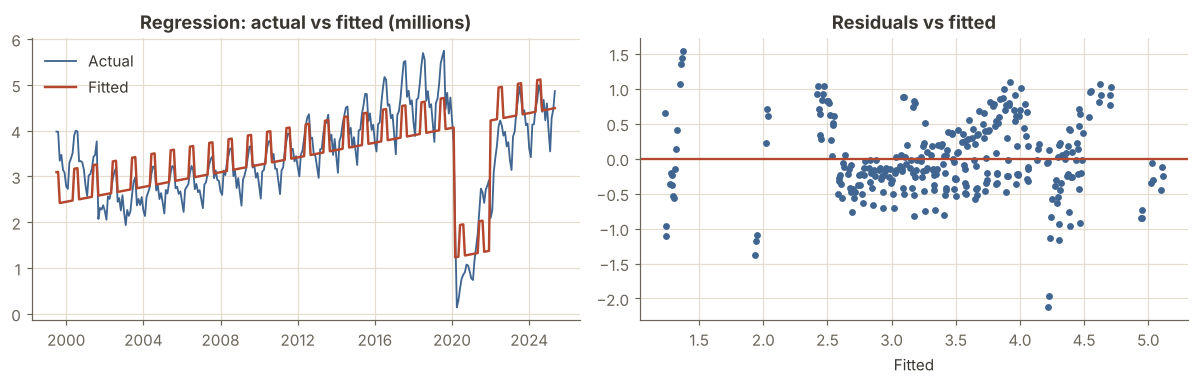

In [15]:
reg = pd.DataFrame({"y": monthly})
reg["t"] = np.arange(len(reg))
reg["summer"] = reg.index.month.isin([6, 7, 8]).astype(int)
reg["covid"] = ((reg.index >= "2020-03-01") & (reg.index <= "2021-12-01")).astype(int)

X = sm.add_constant(reg[["t", "summer", "covid"]])
ols = sm.OLS(reg["y"], X).fit()
print(ols.summary().tables[1])
mape_fit = (np.abs(ols.resid) / reg["y"]).mean() * 100
print(f"R-squared {ols.rsquared:.3f} | adj. {ols.rsquared_adj:.3f} | F-test p = {ols.f_pvalue:.2e}")
print(f"Average in-sample error (MAPE): {mape_fit:.1f}%   | Durbin-Watson: {durbin_watson(ols.resid):.2f}")
results.update(r2=ols.rsquared, adj_r2=ols.rsquared_adj, reg_mape=mape_fit, dw=durbin_watson(ols.resid),
               coef=ols.params.round(4).to_dict(), pvals=ols.pvalues.to_dict(), ci95=ols.conf_int().round(3).values.tolist())
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(reg.index, reg["y"], color=BLUE, lw=1.2, label="Actual"); axes[0].plot(reg.index, ols.fittedvalues, color=RUST, lw=1.6, label="Fitted")
axes[0].legend(frameon=False); axes[0].set_title("Regression: actual vs fitted (millions)")
axes[1].scatter(ols.fittedvalues, ols.resid, color=BLUE, s=12); axes[1].axhline(0, color=RUST)
axes[1].set_title("Residuals vs fitted"); axes[1].set_xlabel("Fitted")
plt.tight_layout(); plt.savefig(FIG + "reg_fit.png"); plt.show()

## 10. Moving averages

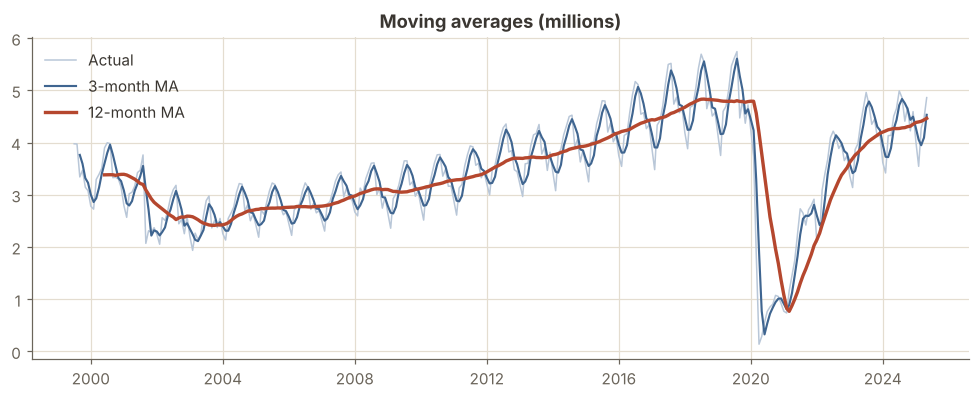

In [16]:
ma = pd.DataFrame({"Actual": monthly, "3-month MA": monthly.rolling(3).mean(), "12-month MA": monthly.rolling(12).mean()})
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(ma["Actual"], color="#B9C7D8", lw=1, label="Actual")
ax.plot(ma["3-month MA"], color=BLUE, lw=1.4, label="3-month MA"); ax.plot(ma["12-month MA"], color=RUST, lw=2.2, label="12-month MA")
ax.legend(frameon=False, loc="upper left"); ax.set_title("Moving averages (millions)")
plt.savefig(FIG + "ma.png"); plt.show()

## 11. Forecasting and model testing
Five methods are compared with a **rolling-origin backtest**: each method is trained up to May of 2014, 2015, 2016, 2017 and 2018, then forecasts the next 12 months, which are compared with the actual values. These test windows stop before COVID-19 so the comparison reflects normal conditions.
Error metric: mean absolute percentage error (MAPE).

                     Method  origin 2014  origin 2015  origin 2016  origin 2017  origin 2018  Average MAPE (%)
      Holt-Winters additive         2.04         1.41         3.11         5.11         4.59              3.25
Holt-Winters multiplicative         2.43         2.50         2.54         5.44         3.38              3.26
             Seasonal naive         4.22         6.04         5.16         6.52         1.78              4.74
           Simple smoothing         8.53         7.68         8.34         7.26        10.74              8.51
          Holt (trend only)         8.61         7.82         8.50         7.28        11.27              8.69


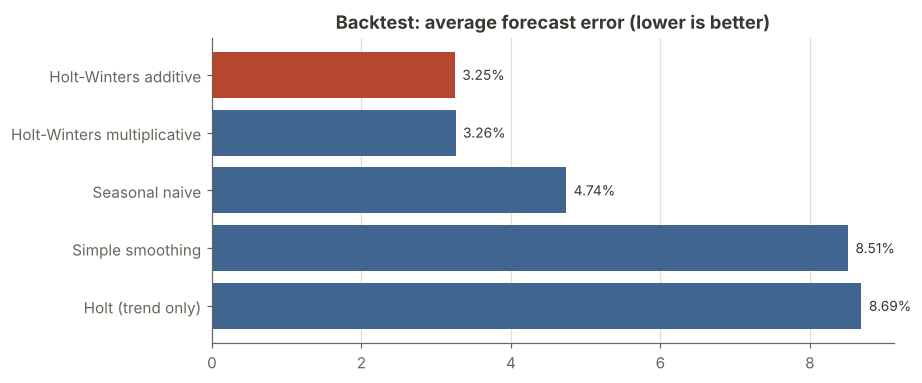

In [17]:
def mape(actual, pred): return float(np.mean(np.abs((actual - pred) / actual)) * 100)

models = {
    "Holt-Winters additive":       lambda tr: ExponentialSmoothing(tr, trend="add", seasonal="add", seasonal_periods=12).fit().forecast(12),
    "Holt-Winters multiplicative": lambda tr: ExponentialSmoothing(tr, trend="add", seasonal="mul", seasonal_periods=12).fit().forecast(12),
    "Seasonal naive":              lambda tr: pd.Series(tr.values[-12:]),
    "Simple smoothing":            lambda tr: SimpleExpSmoothing(tr, initialization_method="estimated").fit().forecast(12),
    "Holt (trend only)":           lambda tr: Holt(tr, initialization_method="estimated").fit().forecast(12),
}
origins = [pd.Timestamp(f"{y}-05-01") for y in range(2014, 2019)]

rows = []
for name, fn in models.items():
    errs = []
    for o in origins:
        train = monthly[:o]; test = monthly[o + pd.DateOffset(months=1):][:12]
        errs.append(mape(test.values, np.asarray(fn(train))))
    rows.append([name] + [round(e, 2) for e in errs] + [round(np.mean(errs), 2)])
bt = pd.DataFrame(rows, columns=["Method"] + [f"origin {o.year}" for o in origins] + ["Average MAPE (%)"]).sort_values("Average MAPE (%)")
print(bt.to_string(index=False))
results["backtest"] = {r[0]: r[-1] for r in rows}
results["backtest_full"] = bt.values.tolist(); results["backtest_cols"] = list(bt.columns)

fig, ax = plt.subplots(figsize=(8, 3.6))
b = bt.iloc[::-1]
ax.barh(b["Method"], b["Average MAPE (%)"], color=[RUST if m == bt.iloc[0]["Method"] else BLUE for m in b["Method"]])
for i, v in enumerate(b["Average MAPE (%)"]): ax.text(v + .1, i, f"{v:.2f}%", va="center", fontsize=9)
ax.grid(axis="y", visible=False); ax.set_title("Backtest: average forecast error (lower is better)")
plt.savefig(FIG + "fc_backtest.png"); plt.show()

Smoothing parameters: {'smoothing_level': np.float64(1.0), 'smoothing_trend': np.float64(0.0), 'smoothing_seasonal': np.float64(0.0)}
Forecast Jun 2025-May 2026: 57.73M | last 12 months: 53.57M | change +7.8% | 2019: 57.42M
80% interval for the 12-month total: 52.5M to 63.1M


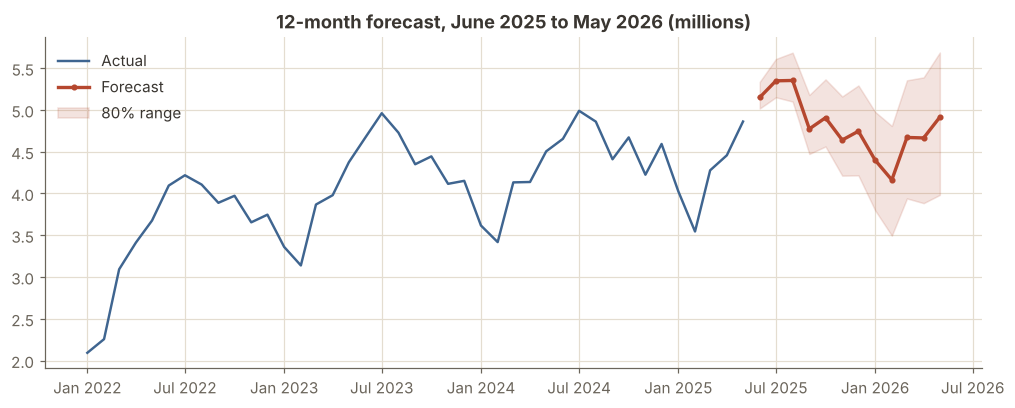

,Forecast (M)
2025-06-01,5.15
2025-07-01,5.35
2025-08-01,5.35
2025-09-01,4.77
2025-10-01,4.91
2025-11-01,4.64
2025-12-01,4.75
2026-01-01,4.40
2026-02-01,4.16
2026-03-01,4.67


In [18]:
# Final model: Holt-Winters (additive) fitted on all 311 months
hw = ExponentialSmoothing(monthly, trend="add", seasonal="add", seasonal_periods=12).fit()
fc = hw.forecast(12)
last12 = monthly[-12:].sum()
total = fc.sum()
print("Smoothing parameters:", {k: round(v, 4) for k, v in hw.params.items() if k in ("smoothing_level", "smoothing_trend", "smoothing_seasonal")})
print(f"Forecast Jun 2025-May 2026: {total:.2f}M | last 12 months: {last12:.2f}M | change {(total/last12-1)*100:+.1f}% | 2019: {results['annual'][2019]:.2f}M")

# Uncertainty: simulate 2,000 possible futures from the fitted model
sims = hw.simulate(12, repetitions=2000, error="add", random_errors="bootstrap", anchor="end", random_state=42)
tot_sims = sims.sum(axis=0)
lo, hi = np.percentile(tot_sims, [10, 90]); print(f"80% interval for the 12-month total: {lo:.1f}M to {hi:.1f}M")
mlo, mhi = np.percentile(sims.values, [10, 90], axis=1)

results.update(fc_total=total, last12=last12, fc_change=(total/last12-1)*100, int_lo=lo, int_hi=hi,
               alpha=hw.params["smoothing_level"], beta=hw.params["smoothing_trend"], gamma=hw.params["smoothing_seasonal"],
               fc_monthly={d.strftime("%b %Y"): round(float(v), 3) for d, v in fc.items()},
               fc_peak=fc.idxmax().strftime("%b %Y"), fc_peak_val=float(fc.max()), fc_low=fc.idxmin().strftime("%b %Y"), fc_low_val=float(fc.min()))

fig, ax = plt.subplots(figsize=(11, 3.9))
ax.plot(monthly["2022-01-01":], color=BLUE, lw=1.6, label="Actual")
ax.plot(fc, color=RUST, lw=2.2, marker="o", ms=3, label="Forecast")
ax.fill_between(fc.index, mlo, mhi, color=RUST, alpha=.15, label="80% range")
ax.legend(frameon=False, loc="upper left"); ax.set_title("12-month forecast, June 2025 to May 2026 (millions)")
import matplotlib.dates as mdates; ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.savefig(FIG + "fc_forecast.png"); plt.show()
fc.round(2).to_frame("Forecast (M)")

In [19]:
# Annual comparison used in the business discussion
comp = pd.Series({"Last 12 months (Jun 2024-May 2025)": last12, "Forecast (Jun 2025-May 2026)": total, "2019 (pre-COVID peak year)": results["annual"][2019]})
print(comp.round(1).to_string())
json.dump(results, open("results.json", "w"), indent=1, default=float)

Last 12 months (Jun 2024-May 2025)    53.6
Forecast (Jun 2025-May 2026)          57.7
2019 (pre-COVID peak year)            57.4


## 12. Business recommendations
1. **Plan capacity from the forecast** (about 57.7M passengers) and keep a safety buffer, since the 80% range is wide enough to matter.
2. **Staff for summer** (June to August run about 21% above other months) and schedule leave and maintenance outside it.
3. **Re-fit every month** with new actuals; the backtest shows the method is accurate only while the seasonal pattern holds.
4. **Watch the post-COVID recovery**: 2024 was still significantly below 2019, so growth assumptions should be checked against fresh data.

## 13. Conclusion
Holt-Winters captured trend and seasonality best in our tests and gives a usable planning estimate.